In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

In [2]:
from google.colab import files
uploaded = files.upload()
FILE = list(uploaded.keys())[0]

Saving india_weather_103cities_30mar_13apr.xlsx to india_weather_103cities_30mar_13apr.xlsx


In [3]:
df = pd.read_excel(FILE)

print("Original Dataset:")
display(df.head())
print("\nDataset Shape:", df.shape)
print("\nData Types:")
print(df.dtypes)

Original Dataset:


,city,latitude,longitude,init_time,timepoint_hr,temperature_c,cloud_cover,lifted_index,precipitation_type,precipitation_amount,relative_humidity,wind_direction,wind_speed,weather,forecast_datetime,forecast_date
0,Agartala,23.831,91.287,2026-03-29 12:00:00,12,22,1,2,rain,0,98,S,2,ishowerday,2026-03-30 00:00:00,2026-03-30
1,Agartala,23.831,91.287,2026-03-29 12:00:00,15,28,1,-1,rain,0,65,S,3,ishowerday,2026-03-30 03:00:00,2026-03-30
2,Agartala,23.831,91.287,2026-03-29 12:00:00,18,33,2,-1,rain,0,54,SW,3,ishowerday,2026-03-30 06:00:00,2026-03-30
3,Agartala,23.831,91.287,2026-03-29 12:00:00,21,30,8,-1,none,0,51,S,3,cloudyday,2026-03-30 09:00:00,2026-03-30
4,Agartala,23.831,91.287,2026-03-29 12:00:00,24,26,6,-1,rain,0,82,SW,3,oshowerday,2026-03-30 12:00:00,2026-03-30



Dataset Shape: (12360, 16)

Data Types:
city                            object
latitude                       float64
longitude                      float64
init_time               datetime64[ns]
timepoint_hr                     int64
temperature_c                    int64
cloud_cover                      int64
lifted_index                     int64
precipitation_type              object
precipitation_amount             int64
relative_humidity                int64
wind_direction                  object
wind_speed                       int64
weather                         object
forecast_datetime       datetime64[ns]
forecast_date           datetime64[ns]
dtype: object


In [4]:
df["weather_condition"] = (
    df["weather"]
    .str.replace("day", "", regex=False)
    .str.replace("night", "", regex=False)
)

counts = df["weather_condition"].value_counts()
rare = counts[counts < 100].index
df["weather_condition"] = df["weather_condition"].replace({r: "other" for r in rare})


df["hour_of_day"] = df["forecast_datetime"].dt.hour
df["day_of_month"] = df["forecast_datetime"].dt.day
df["is_night"] = df["weather"].str.endswith("night").astype(int)

df = df.drop(columns=["weather", "city", "init_time",
                      "forecast_datetime", "forecast_date"])

target = "weather_condition"

print("Dependent Variable:", target)
print("Independent Variables:")
print([c for c in df.columns if c != target])
print("\nClass distribution:")
print(df[target].value_counts())

Dependent Variable: weather_condition
Independent Variables:
['latitude', 'longitude', 'timepoint_hr', 'temperature_c', 'cloud_cover', 'lifted_index', 'precipitation_type', 'precipitation_amount', 'relative_humidity', 'wind_direction', 'wind_speed', 'hour_of_day', 'day_of_month', 'is_night']

Class distribution:
weather_condition
clear        4565
cloudy       2267
mcloudy      2245
ts           1092
lightrain     782
pcloudy       715
ishower       397
oshower       207
other          90
Name: count, dtype: int64


In [5]:
print("Missing Values Before Cleaning:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()
df = df.dropna(subset=[target])

for col in df.columns:
    if col == target:
        continue
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode().iloc[0])

print("\nDataset Shape After Cleaning:", df.shape)
print("Missing Values After Cleaning:", df.isnull().sum().sum())

Missing Values Before Cleaning:
latitude                0
longitude               0
timepoint_hr            0
temperature_c           0
cloud_cover             0
lifted_index            0
precipitation_type      0
precipitation_amount    0
relative_humidity       0
wind_direction          0
wind_speed              0
weather_condition       0
hour_of_day             0
day_of_month            0
is_night                0
dtype: int64

Duplicate Rows: 0

Dataset Shape After Cleaning: (12360, 15)
Missing Values After Cleaning: 0


In [6]:
X = pd.get_dummies(df.drop(columns=[target]), dtype=int, drop_first=True)
X = X.loc[:, X.nunique() > 1]

le = LabelEncoder()
y = le.fit_transform(df[target])
classes = list(le.classes_)

print("X shape:", X.shape, "| y shape:", y.shape)
print("Classes:", classes)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)

X shape: (12360, 21) | y shape: (12360,)
Classes: ['clear', 'cloudy', 'ishower', 'lightrain', 'mcloudy', 'oshower', 'other', 'pcloudy', 'ts']
Train: (9888, 21) Test: (2472, 21)


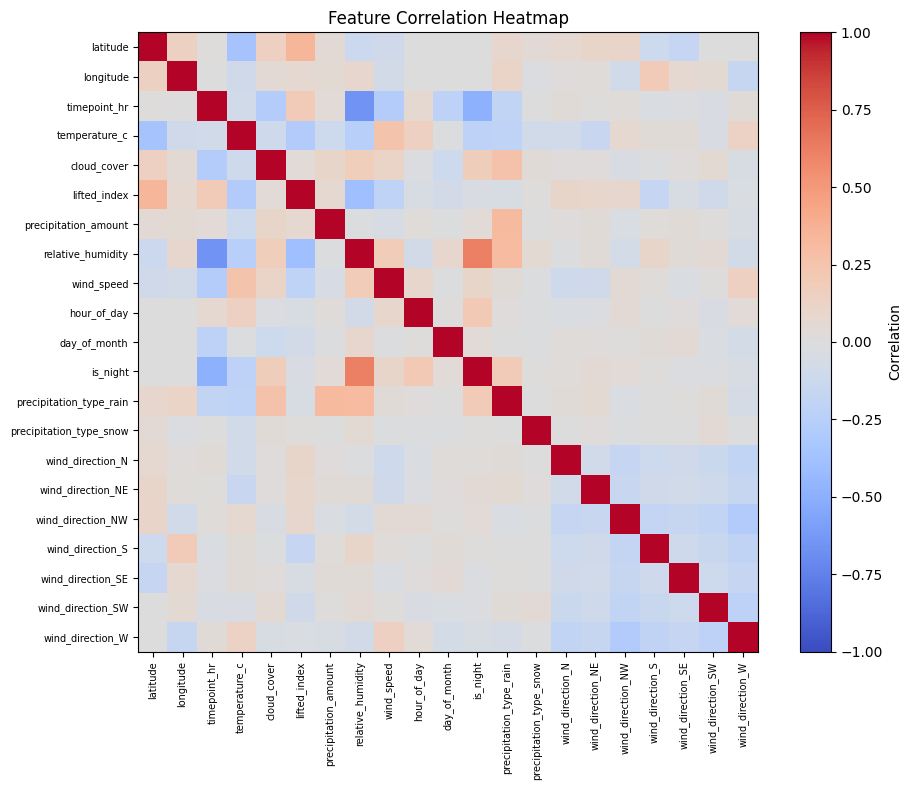

Top correlated feature pairs:
timepoint_hr          relative_humidity          0.651266
relative_humidity     is_night                   0.610149
timepoint_hr          is_night                   0.488819
lifted_index          relative_humidity          0.383198
latitude              temperature_c              0.356188
                      lifted_index               0.341306
precipitation_amount  precipitation_type_rain    0.314451
relative_humidity     precipitation_type_rain    0.312132
wind_direction_NW     wind_direction_W           0.284994
temperature_c         lifted_index               0.282574
dtype: float64


In [7]:
corr = X.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90, fontsize=7)
plt.yticks(range(len(corr.columns)), corr.columns, fontsize=7)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
print("Top correlated feature pairs:")
print(upper.stack().abs().sort_values(ascending=False).head(10))

In [8]:
K = 5

skb = SelectKBest(f_classif, k=K).fit(X_train, y_train)
filter_scores = pd.Series(skb.scores_, index=X_train.columns).sort_values(ascending=False)
filter_features = list(X_train.columns[skb.get_support()])

print("ANOVA F-scores:")
print(filter_scores.round(1))
print("\nFilter Selected Features:", filter_features)

ANOVA F-scores:
precipitation_type_rain    17650.1
cloud_cover                 4555.8
relative_humidity            504.2
precipitation_amount         471.0
timepoint_hr                 451.4
is_night                     173.3
lifted_index                 114.9
temperature_c                 83.8
precipitation_type_snow       72.1
wind_speed                    63.8
latitude                      47.8
longitude                     31.8
day_of_month                  25.0
hour_of_day                   18.2
wind_direction_NW             10.6
wind_direction_S               9.3
wind_direction_W               8.1
wind_direction_SW              5.1
wind_direction_N               4.5
wind_direction_NE              2.8
wind_direction_SE              2.3
dtype: float64

Filter Selected Features: ['timepoint_hr', 'cloud_cover', 'precipitation_amount', 'relative_humidity', 'precipitation_type_rain']


In [9]:
scaler = StandardScaler().fit(X_train)
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns)

rfe = RFE(LogisticRegression(max_iter=2000), n_features_to_select=K)
rfe.fit(X_train_scaled, y_train)
rfe_features = list(X_train.columns[rfe.support_])

print("RFE Selected Features:", rfe_features)

RFE Selected Features: ['timepoint_hr', 'cloud_cover', 'precipitation_amount', 'relative_humidity', 'precipitation_type_rain']


Tree-Based Selected Features: ['cloud_cover', 'precipitation_type_rain', 'precipitation_amount', 'timepoint_hr', 'relative_humidity']


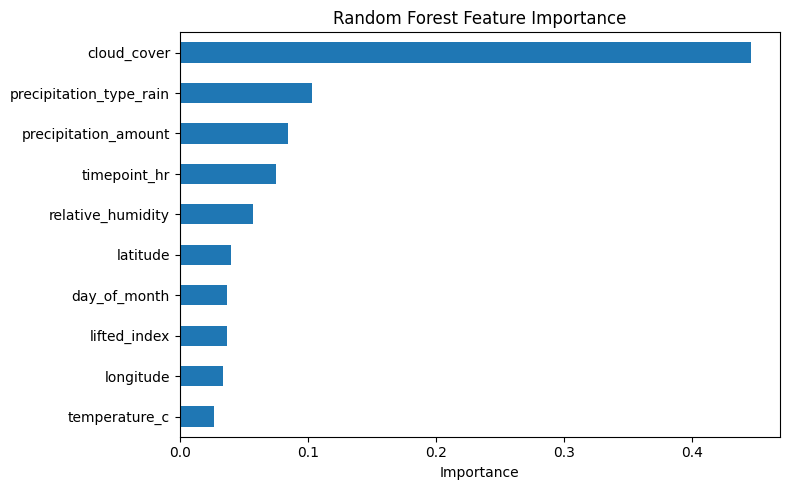

In [10]:
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

importance = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
tree_features = list(importance.head(K).index)

print("Tree-Based Selected Features:", tree_features)

importance.head(10)[::-1].plot(kind="barh", figsize=(8, 5))
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [11]:
comparison = pd.DataFrame({
    "Filter": X_train.columns.isin(filter_features),
    "RFE": X_train.columns.isin(rfe_features),
    "Tree": X_train.columns.isin(tree_features),
}, index=X_train.columns)
comparison["Votes"] = comparison.sum(axis=1)

print("Feature Selection Comparison:")
display(comparison.sort_values("Votes", ascending=False))

common = sorted(set(filter_features) & set(rfe_features) & set(tree_features))
print("\nFeatures chosen by all three methods:", common)

Feature Selection Comparison:


,Filter,RFE,Tree,Votes
timepoint_hr,True,True,True,3
cloud_cover,True,True,True,3
precipitation_type_rain,True,True,True,3
relative_humidity,True,True,True,3
precipitation_amount,True,True,True,3
temperature_c,False,False,False,0
longitude,False,False,False,0
latitude,False,False,False,0
lifted_index,False,False,False,0
wind_speed,False,False,False,0



Features chosen by all three methods: ['cloud_cover', 'precipitation_amount', 'precipitation_type_rain', 'relative_humidity', 'timepoint_hr']


Model Performance Comparison:


,Model,Feature Count,Accuracy,Weighted F1
0,All Features,21,0.9539,0.9539
1,Filter Features,5,0.9292,0.9288
2,RFE Features,5,0.9292,0.9288
3,Tree Features,5,0.9300,0.9295


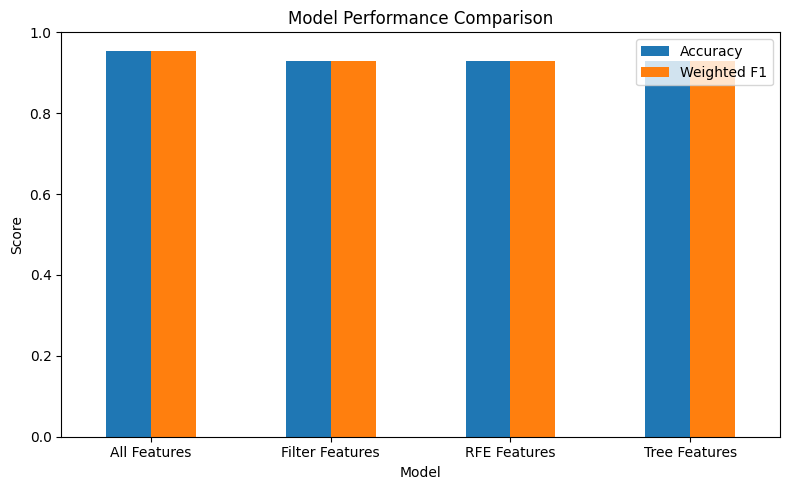

Experiment Completed Successfully.


In [12]:
def evaluate(name, features):
    model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    model.fit(X_train[features], y_train)
    pred = model.predict(X_test[features])
    return {
        "Model": name,
        "Feature Count": len(features),
        "Accuracy": accuracy_score(y_test, pred),
        "Weighted F1": f1_score(y_test, pred, average="weighted"),
    }

results = pd.DataFrame([
    evaluate("All Features", list(X_train.columns)),
    evaluate("Filter Features", filter_features),
    evaluate("RFE Features", rfe_features),
    evaluate("Tree Features", tree_features),
])

print("Model Performance Comparison:")
display(results.round(4))

results.set_index("Model")[["Accuracy", "Weighted F1"]].plot(
    kind="bar", ylim=(0, 1), figsize=(8, 5)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Experiment Completed Successfully.")